# Reading Abaqus meshes with pyramids-mesh

**Abaqus** (Dassault Systèmes) input decks (`.inp`) drive one of the most widely used finite-element solvers. They are **keyword ASCII** files: a `*NODE` block lists coordinates, and `*ELEMENT, TYPE=...` blocks list connectivity.

Our sample uses `TYPE=CPS3` — 3-node plane-stress triangles. Coordinates are in the model's engineering frame with no projection, so **`crs=None`**.

We use `nle1xf3c.inp`: a small all-triangle plane-stress patch.

> Source: meshio test suite (`tests/meshes/abaqus/`), MIT.

## Set up plotting

pyramids draws through **cleopatra** (its matplotlib layer). Under a headless `Agg` backend a figure renders but is never shown, so we add a tiny `show()` helper that captures the current figure and embeds it as a PNG after every plot.

In [1]:
import os
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

## Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
import numpy as np
import geopandas as gpd
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")  # resolved relative to THIS notebook
DATA

WindowsPath('../../examples/data')

## Quickstart: read the Abaqus file

`driver="abaqus"` parses the keyword grammar (`*NODE` / `*ELEMENT`).

The one rule that matters: **pass a `pathlib.Path`, never a `str`** — `read_file` keys its driver dispatch off the `Path` type. `UgridDataset.read_file(...)` returns a `UgridDataset`, the in-memory UGRID container every pyramids-mesh driver produces.

In [3]:
ds = UgridDataset.read_file(DATA / "abaqus" / "nle1xf3c.inp", driver="abaqus")
ds

UgridDataset(mesh='mesh2d', n_node=12, n_face=12, n_edge=0, variables=[])

## What did we get?

A few scalar properties describe the dataset at a glance: node and face counts, the coordinate reference system, and the planar bounding box.

In [4]:
print("n_node :", ds.n_node)
print("n_face :", ds.n_face)
print("crs    :", ds.crs)
print("epsg   :", ds.epsg)
print("data   :", ds.data_variable_names)
print("bounds :", ds.bounds)

n_node : 12
n_face : 12
crs    : None
epsg   : None
data   : []
bounds : (0.0, 0.0, 3.25, 2.75)


`crs`/`epsg` are `None`. There are **no data variables** — the deck is pure geometry. 12 nodes and 12 `CPS3` triangles span a small `3.25×2.75` patch.

### Summary table

`ds.summary()` returns a pandas `DataFrame` with per-variable statistics (count / min / max / mean / std). With no data variables the table is empty — confirming a geometry-only deck.

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,


## The mesh geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the **face-node connectivity**, an `(n_face, k)` integer table where `k` is the largest number of nodes any face has. Triangles fill 3 columns; quadrilaterals fill 4 (a shorter face pads the spare slot). `face_areas` and `face_centroids` are derived on demand.

In [6]:
mesh = ds.mesh
fnc = mesh.face_node_connectivity.data
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)       # shape (2, n_face)
print("mesh type         :", type(mesh).__name__)
print("connectivity shape:", fnc.shape)
print("node_x range      :", float(mesh.node_x.min()), "->", float(mesh.node_x.max()))
print("node_y range      :", float(mesh.node_y.min()), "->", float(mesh.node_y.max()))
print("face_areas        :", float(areas.min()), "->", float(areas.max()))
print("centroids shape   :", cent.shape)

mesh type         : Mesh2d
connectivity shape: (12, 3)
node_x range      : 0.0 -> 3.25
node_y range      : 0.0 -> 2.75
face_areas        : 0.1415624840625 -> 0.7800625481250001
centroids shape   : (2, 12)


The connectivity is `(12, 3)`: **12 triangles, three nodes each** — the `CPS3` elements. Areas vary across the patch, so the elements are not uniform.

## Wireframe

`plot_outline()` draws the bare mesh edges — the quickest way to eyeball the topology and the element shapes before colouring anything.

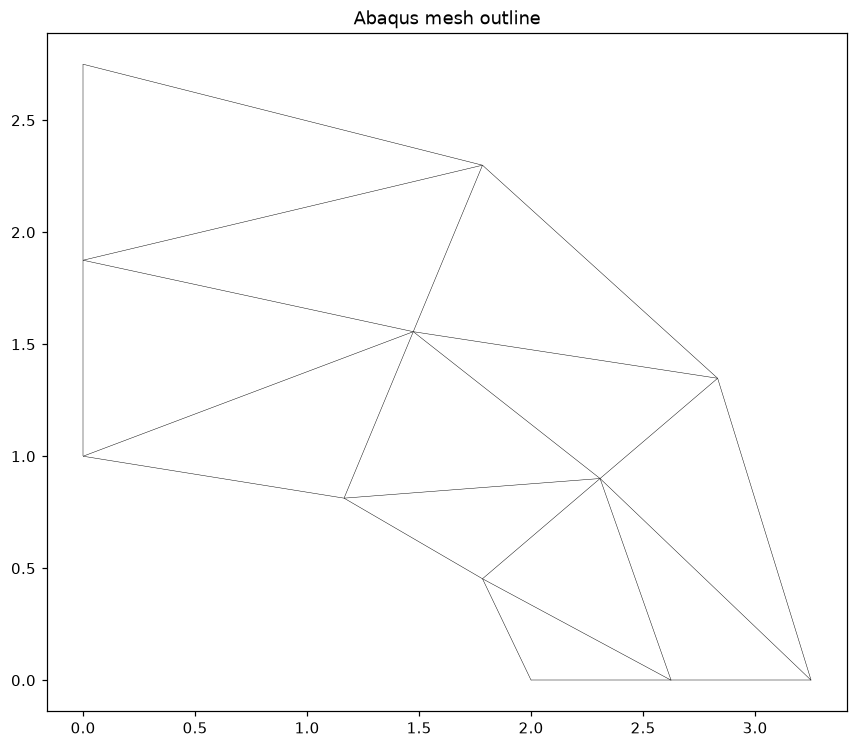

In [7]:
ds.plot_outline()
plt.title("Abaqus mesh outline")
show()

## A derived field: cell area

These engineering files usually carry **no cell data** we can colour by — so we compute one ourselves. `with_variable` attaches `face_areas` as a face-located variable, giving a non-destructive copy of the dataset that `plot` can render as a filled colour map.

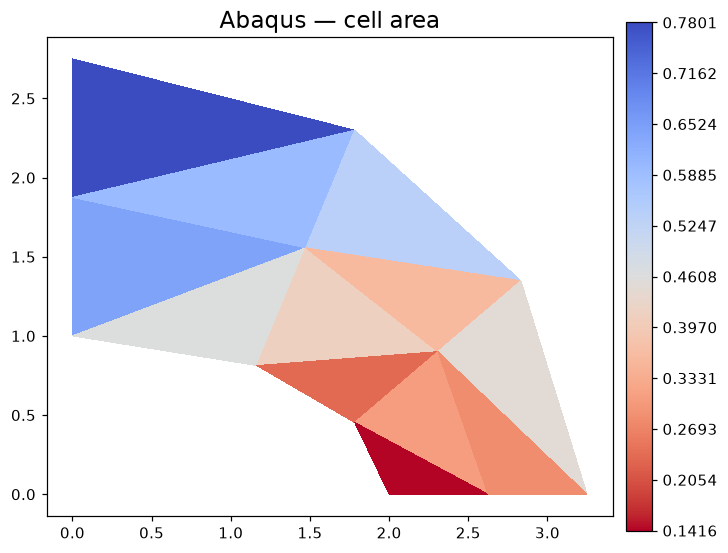

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Abaqus — cell area")
show()

The colour map shows the graded triangle sizes across the plane-stress patch — finer where the analyst wanted resolution.

## Treating the mesh as GIS

Because a `UgridDataset` is just nodes and polygonal faces, pyramids exposes the usual vector-GIS toolbox on it. First, every face as a GeoPandas polygon:

In [9]:
gdf = ds.to_geodataframe()
print(type(gdf).__name__, gdf.shape)
gdf.head()

GeoDataFrame (12, 1)


,geometry
0,"POLYGON ((1.474 1.55602, 0 1.875, 0 1, 1.474 1..."
1,"POLYGON ((0 1, 1.165 0.81283, 1.474 1.55602, 0..."
2,"POLYGON ((2.30791 0.9005, 1.474 1.55602, 1.165..."
3,"POLYGON ((1.165 0.81283, 1.78302 0.453, 2.3079..."
4,"POLYGON ((2.625 0, 2.30791 0.9005, 1.78302 0.4..."


Being a real `GeoDataFrame`, it plots with GeoPandas directly — a filled view of every element footprint:

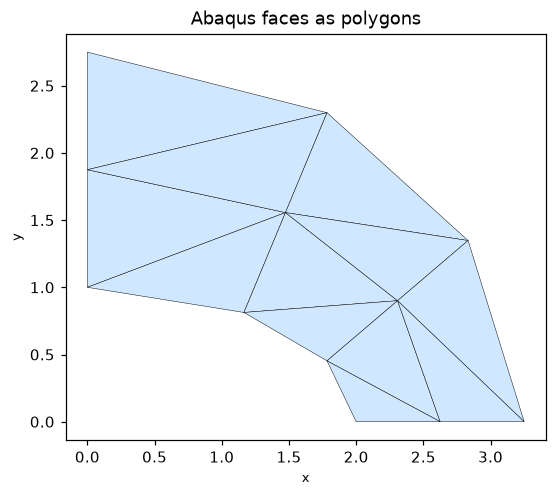

In [10]:
gdf.plot(edgecolor="black", linewidth=0.3, facecolor="#cfe8ff")
plt.title("Abaqus faces as polygons"); plt.gca().set_aspect("equal")
show()

### The outer boundary

`bounding_polygon()` dissolves the triangles into the patch outline.

geometry type: Polygon


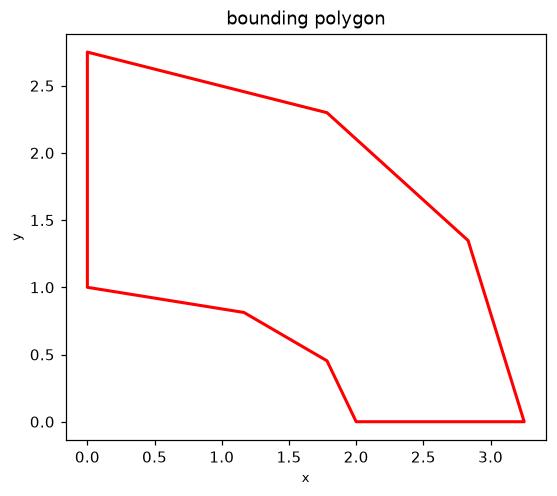

In [11]:
poly = ds.bounding_polygon()
print("geometry type:", poly.geom_type)
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="red", linewidth=2)
plt.gca().set_aspect("equal"); plt.title("bounding polygon"); show()

### Cropping to a bounding box

`crop(bbox=...)` returns a new `UgridDataset` with only the faces inside the box — handy for zooming into a region of a large mesh. We crop to the left half of the extent.

faces before / after: 12 -> 4


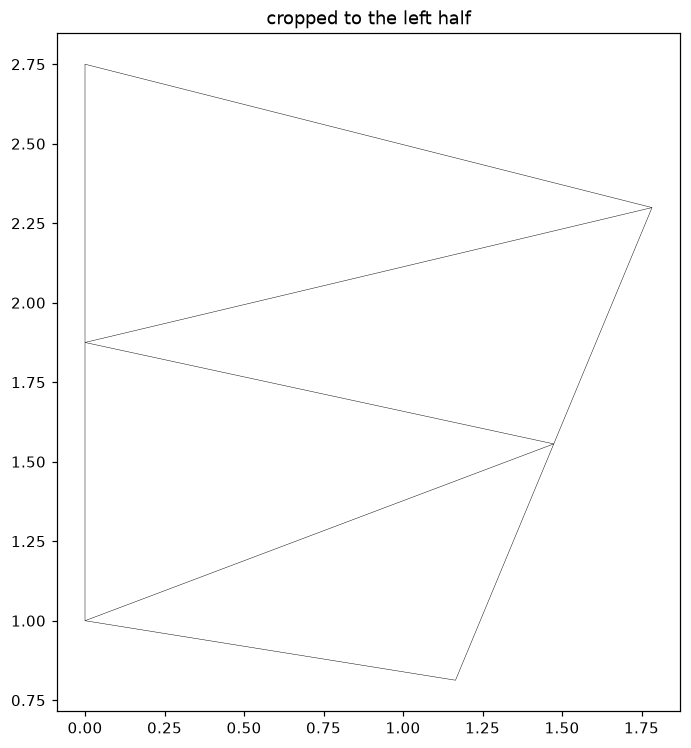

In [12]:
xmin, ymin, xmax, ymax = ds.bounds
half = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
print("faces before / after:", ds.n_face, "->", half.n_face)
half.plot_outline(); plt.title("cropped to the left half"); show()

### The face-adjacency graph

`sparse_adjacency()` gives the face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels which faces are reachable from which. `plt.spy` shows the sparsity pattern — the fingerprint of how the faces are wired together.

adjacency: (12, 12) nnz = 26
connected components: 1


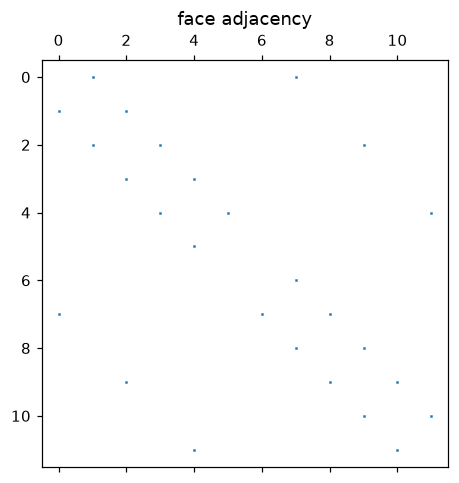

In [13]:
adj = ds.sparse_adjacency()
comp = np.asarray(ds.connected_components())
print("adjacency:", adj.shape, "nnz =", adj.nnz)
print("connected components:", np.unique(comp).size)
plt.spy(adj, markersize=0.6); plt.title("face adjacency"); show()

The triangles form one connected patch (a single component); the spy plot shows each interior triangle linked to its edge neighbours.

### A triangle-only operation: circumcenters

Every `CPS3` element is a triangle, so `circumcenters()` is defined. We overlay the circumcenters (red) on the area-weighted centroids (blue) — note how they diverge for the more skewed triangles.

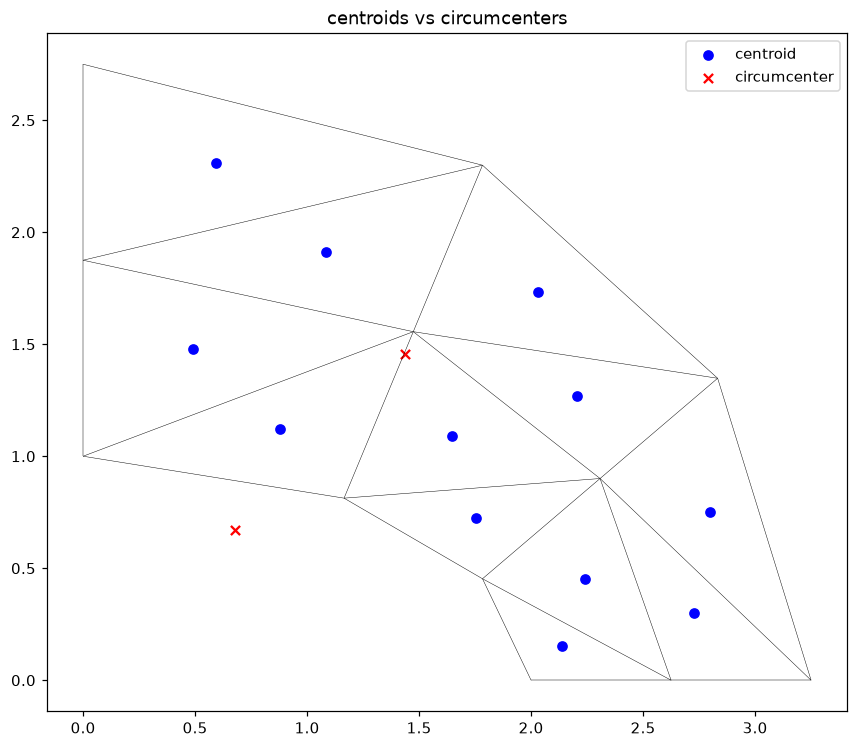

In [14]:
cc = np.asarray(ds.circumcenters())
ct = np.asarray(ds.mesh.face_centroids)
ds.plot_outline()
plt.scatter(ct[0], ct[1], c="blue", label="centroid")
plt.scatter(cc[0], cc[1], c="red", marker="x", label="circumcenter")
plt.legend(); plt.title("centroids vs circumcenters"); show()

### Converting out: xarray and other drivers

`to_xarray()` hands the whole UGRID dataset to xarray (dimensions named the CF-UGRID way), and `to_file(path, driver=...)` re-serialises it through any writer in the driver table — here a round-trip to the `2dm` format in a temp file.

In [15]:
import tempfile
xd = ds.to_xarray()
print("xarray dims:", dict(xd.sizes))
out = Path(tempfile.gettempdir()) / "abaqus_roundtrip.2dm"
ds.to_file(out, driver="2dm")
print("wrote:", out.name, "| exists:", out.exists())

xarray dims: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 12, 'mesh2d_nFaces': 12, 'mesh2d_nMaxFaceNodes': 3}
wrote: abaqus_roundtrip.2dm | exists: True


### What we cannot do here: reprojection & regridding

`to_crs(epsg)` reprojects between coordinate systems — but this mesh has **`crs=None`** (model-local coordinates, no datum), so there is nothing to reproject from; we skip it. Likewise `rasterize_like(...)` and `regrid(...)` map a *data field* onto a raster or another mesh; with no meaningful field and no georeferencing on an engineering mesh they are out of scope. These belong on georeferenced hydrodynamic meshes, not FEM/CFD decks.

## Takeaway

- `driver="abaqus"` reads a keyword `.inp` deck (`*NODE` + `*ELEMENT TYPE=CPS3`) into a `UgridDataset`.
- An all-triangle plane-stress patch, geometry-only (`crs=None`, no data variables).
- All GIS operations work, and because it is triangular, `circumcenters` does too.
- No CRS → reprojection and regridding do not apply.